# BurnInWatch — Experiment-Aware Preprocessing & First Feature Engineering

## Why we are doing this

The EDA showed that the dataset is not a simple stationary table.

Important observations:
- `supplyVoltage`, `node1Voltage`, and `node2Voltage` have step-like operating-condition changes.
- `packageTemperature` has large operating-stage changes.
- `collectorEmitterCurrent` is noisy and has spikes.
- `heatSinkTemperature` and `internalTemperature` have unusual numerical scales and should not be interpreted as physical °C until confirmed by the experiment documentation.
- Files have gaps between experiments, so we must **not calculate trends across file boundaries**.
- `ambientTemperature` is completely unavailable in these steady-state records.
- `main`, `b`, and `check` are filename-derived metadata only; they are NOT anomaly labels.

The goal of this notebook is to prepare the data without destroying information or creating artificial labels.

We will:
1. preserve raw values
2. handle structural missingness
3. create safe per-file elapsed time
4. create operating-condition context
5. segment records into fixed temporal windows **within each source file**
6. calculate robust window-level features
7. inspect the resulting feature space

**No anomaly model is trained here.**

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

PROCESSED = Path("processed")
INPUT = PROCESSED / "burninwatch_aging_canonical_v1.csv"

aging = pd.read_csv(INPUT)

ENGINEERING_FIELDS = [
    "supplyVoltage",
    "node1Voltage",
    "node2Voltage",
    "collectorEmitterCurrent",
    "heatSinkTemperature",
    "packageTemperature",
    "internalTemperature",
]

print("Input shape:", aging.shape)

Input shape: (68761, 15)


## 1. Remove only structural missingness

`ambientTemperature` has no valid observations in this dataset, so it cannot currently contribute information.

We remove that column from the modeling candidate set, but we do **not** alter the original CSV.

In [2]:
MODEL_SIGNAL_FIELDS = [
    "supplyVoltage",
    "node1Voltage",
    "node2Voltage",
    "collectorEmitterCurrent",
    "heatSinkTemperature",
    "packageTemperature",
    "internalTemperature",
]

DROP_STRUCTURALLY_MISSING = ["ambientTemperature"]

print("Structural missingness:")
display(
    aging[DROP_STRUCTURALLY_MISSING].isna().mean().to_frame("missing_fraction")
)

work = aging.drop(columns=DROP_STRUCTURALLY_MISSING).copy()

print("Working columns:")
print(work.columns.tolist())

Structural missingness:


,missing_fraction
ambientTemperature,1.0


Working columns:
['device_id', 'file_name', 'file_role', 'event_index', 'date', 'timeEpoch', 'supplyVoltage', 'node1Voltage', 'node2Voltage', 'collectorEmitterCurrent', 'heatSinkTemperature', 'packageTemperature', 'internalTemperature', 'measurement_valid']


## 2. Safe per-file time

A major issue discovered in EDA was the presence of large gaps between separate files.

For example, a `check` file may happen much later than the preceding `main` file.

Therefore, for trend calculations we create:

`elapsed_file_seconds`

using the first timestamp **inside each physical source file**.

We do NOT calculate slopes across `main → b → check` boundaries in this notebook.

In [3]:
work["timeEpoch"] = pd.to_numeric(work["timeEpoch"], errors="coerce")

work = work.sort_values(
    ["device_id", "file_name", "event_index"]
).reset_index(drop=True)

work["elapsed_file_seconds"] = (
    work.groupby(["device_id", "file_name"])["timeEpoch"]
    .transform(lambda s: s - s.min())
)

work["elapsed_file_minutes"] = work["elapsed_file_seconds"] / 60.0

display(
    work.groupby(["device_id", "file_name", "file_role"])
    .agg(
        records=("event_index", "size"),
        duration_min=("elapsed_file_minutes", "max"),
        first_time=("timeEpoch", "min"),
        last_time=("timeEpoch", "max")
    )
    .reset_index()
)

,device_id,file_name,file_role,records,duration_min,first_time,last_time
0,Device_2,Device2 1.mat,main,10977,41.688733,3.312986e+09,3.312989e+09
1,Device_2,Device2b 1.mat,b,6434,24.858067,3.312989e+09,3.312991e+09
2,Device_2,Device2check 1.mat,check,116,0.510350,3.313009e+09,3.313009e+09
3,Device_3,Device3 1.mat,main,9836,37.786200,3.313005e+09,3.313007e+09
4,Device_3,Device3b 1.mat,b,5238,19.980033,3.313007e+09,3.313008e+09
5,Device_3,Device3check 1.mat,check,112,0.419850,3.313008e+09,3.313008e+09
6,Device_4,Device4 1.mat,main,10770,41.005883,3.313009e+09,3.313011e+09
7,Device_4,Device4b 1.mat,b,14607,55.846850,3.313012e+09,3.313016e+09
8,Device_5,Device5 1.mat,main,10510,39.767317,3.312994e+09,3.312997e+09
9,Device_5,Device5check 1.mat,check,161,0.631183,3.313009e+09,3.313009e+09


## 3. Keep only rows with enough information

We do not aggressively impute the dataset.

A row is retained when it has at least **5 of the 7 candidate signals** available.

The threshold is deliberately conservative and can be changed after inspecting the actual missingness.

In [4]:
available_count = work[MODEL_SIGNAL_FIELDS].notna().sum(axis=1)

work["available_signal_count"] = available_count

before = len(work)
work = work[available_count >= 5].copy()
after = len(work)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 68761
Rows after: 68761
Rows removed: 0


## 4. Operating-condition context

The EDA shows voltage and package temperature are strongly structured by the experimental operating stages.

We create context variables from the observed measurements rather than calling them anomalies:

- `supply_voltage_round` — coarse voltage regime
- `package_temp_bin` — coarse thermal regime

These are primarily for EDA and conditional feature analysis.

They are not automatically used as model features until we inspect leakage and physical meaning.

In [5]:
work["supply_voltage_round"] = (
    work["supplyVoltage"]
    .round(1)
)

work["package_temp_bin"] = pd.cut(
    work["packageTemperature"],
    bins=[-np.inf, 75, 125, 175, 225, 250, 275, 300, np.inf],
    labels=[
        "<=75",
        "75-125",
        "125-175",
        "175-225",
        "225-250",
        "250-275",
        "275-300",
        ">300"
    ]
)

display(
    work[["supplyVoltage", "supply_voltage_round",
          "packageTemperature", "package_temp_bin"]].head(20)
)

,supplyVoltage,supply_voltage_round,packageTemperature,package_temp_bin
0,2.447730,2.4,30.404121,<=75
1,2.443545,2.4,30.145092,<=75
2,2.461683,2.5,30.080334,<=75
3,2.461683,2.5,30.209849,<=75
4,2.456102,2.5,30.371743,<=75
5,2.458892,2.5,30.177471,<=75
6,2.460287,2.5,30.566015,<=75
7,2.461683,2.5,30.776476,<=75
8,2.443545,2.4,30.485068,<=75
9,2.449125,2.4,31.084073,<=75


## 5. Windowing strategy

The raw steady-state events are not independent component samples.

We create **non-overlapping windows within each source file**.

Default:
- 100 records per window

At a median interval of about 0.2 seconds in the steady-state data, 100 records represent roughly 20 seconds in typical sections.

This is only an initial window size. We will test whether 50, 100, 250, or 500 records gives a more meaningful representation.

In [6]:
WINDOW_SIZE = 100
MIN_WINDOW_SIZE = 50

group_cols = ["device_id", "file_name"]

work = work.sort_values(group_cols + ["event_index"]).copy()

work["window_index"] = (
    work.groupby(group_cols).cumcount() // WINDOW_SIZE
)

work["window_pos"] = (
    work.groupby(group_cols).cumcount() % WINDOW_SIZE
)

window_groups = work.groupby(
    group_cols + ["window_index"],
    sort=False
)

window_sizes = window_groups.size()

print("Number of windows:", len(window_sizes))
print("Window-size distribution:")
display(window_sizes.describe())

print("\nWindows meeting minimum size:", int((window_sizes >= MIN_WINDOW_SIZE).sum()))

Number of windows: 694
Window-size distribution:


count    694.000000
mean      99.079251
std        8.165553
min        7.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
dtype: float64


Windows meeting minimum size: 687


## 6. Robust window features

For each engineering signal we calculate:

- mean
- median
- standard deviation
- minimum
- maximum
- interquartile range
- 5th percentile
- 95th percentile
- absolute median deviation
- linear trend/slope versus time

The slope is calculated **inside one source file/window only**.

This lets us represent both:
- the current operating state
- local changes in behavior

In [7]:
def linear_slope(group, value_col):
    x = pd.to_numeric(
        group["elapsed_file_seconds"], errors="coerce"
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        group[value_col], errors="coerce"
    ).to_numpy(dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)

    if valid.sum() < 3:
        return np.nan

    x = x[valid]
    y = y[valid]

    # Avoid a slope calculation when the time axis has no spread.
    if np.ptp(x) == 0:
        return np.nan

    return float(np.polyfit(x, y, 1)[0])


feature_rows = []

for keys, group in window_groups:
    device_id, file_name, window_index = keys

    row = {
        "device_id": device_id,
        "file_name": file_name,
        "window_index": int(window_index),
        "window_size": len(group),
        "window_start_event": int(group["event_index"].min()),
        "window_end_event": int(group["event_index"].max()),
        "window_start_seconds": float(group["elapsed_file_seconds"].min()),
        "window_end_seconds": float(group["elapsed_file_seconds"].max()),
        "file_role": group["file_role"].iloc[0],
    }

    for signal in MODEL_SIGNAL_FIELDS:
        s = pd.to_numeric(group[signal], errors="coerce").dropna()

        if len(s) == 0:
            continue

        q25 = s.quantile(0.25)
        q75 = s.quantile(0.75)
        median = s.median()

        row[f"{signal}_mean"] = s.mean()
        row[f"{signal}_median"] = median
        row[f"{signal}_std"] = s.std(ddof=0)
        row[f"{signal}_min"] = s.min()
        row[f"{signal}_max"] = s.max()
        row[f"{signal}_q05"] = s.quantile(0.05)
        row[f"{signal}_q95"] = s.quantile(0.95)
        row[f"{signal}_iqr"] = q75 - q25
        row[f"{signal}_mad"] = np.median(np.abs(s - median))
        row[f"{signal}_slope"] = linear_slope(group, signal)

    # Useful consistency features.
    if {"supplyVoltage_mean", "node1Voltage_mean"}.issubset(row):
        row["supply_node1_mean_diff"] = (
            row["supplyVoltage_mean"] -
            row["node1Voltage_mean"]
        )

    if {"node1Voltage_mean", "node2Voltage_mean"}.issubset(row):
        row["node1_node2_mean_diff"] = (
            row["node1Voltage_mean"] -
            row["node2Voltage_mean"]
        )

    # Collector-emitter apparent electrical power proxy.
    if {
        "node2Voltage_mean",
        "collectorEmitterCurrent_mean"
    }.issubset(row):
        row["estimated_power_proxy"] = (
            row["node2Voltage_mean"] *
            row["collectorEmitterCurrent_mean"]
        )

    feature_rows.append(row)


features = pd.DataFrame(feature_rows)

# Remove tiny tail windows.
features = features[
    features["window_size"] >= MIN_WINDOW_SIZE
].reset_index(drop=True)

print("Feature matrix shape:", features.shape)
display(features.head())

Feature matrix shape: (687, 82)


,device_id,file_name,window_index,window_size,window_start_event,window_end_event,window_start_seconds,window_end_seconds,file_role,supplyVoltage_mean,supplyVoltage_median,supplyVoltage_std,supplyVoltage_min,supplyVoltage_max,supplyVoltage_q05,supplyVoltage_q95,supplyVoltage_iqr,supplyVoltage_mad,supplyVoltage_slope,node1Voltage_mean,node1Voltage_median,node1Voltage_std,node1Voltage_min,node1Voltage_max,node1Voltage_q05,node1Voltage_q95,node1Voltage_iqr,node1Voltage_mad,node1Voltage_slope,node2Voltage_mean,node2Voltage_median,node2Voltage_std,node2Voltage_min,node2Voltage_max,node2Voltage_q05,node2Voltage_q95,node2Voltage_iqr,node2Voltage_mad,node2Voltage_slope,collectorEmitterCurrent_mean,collectorEmitterCurrent_median,collectorEmitterCurrent_std,collectorEmitterCurrent_min,collectorEmitterCurrent_max,collectorEmitterCurrent_q05,collectorEmitterCurrent_q95,collectorEmitterCurrent_iqr,collectorEmitterCurrent_mad,collectorEmitterCurrent_slope,heatSinkTemperature_mean,heatSinkTemperature_median,heatSinkTemperature_std,heatSinkTemperature_min,heatSinkTemperature_max,heatSinkTemperature_q05,heatSinkTemperature_q95,heatSinkTemperature_iqr,heatSinkTemperature_mad,heatSinkTemperature_slope,packageTemperature_mean,packageTemperature_median,packageTemperature_std,packageTemperature_min,packageTemperature_max,packageTemperature_q05,packageTemperature_q95,packageTemperature_iqr,packageTemperature_mad,packageTemperature_slope,internalTemperature_mean,internalTemperature_median,internalTemperature_std,internalTemperature_min,internalTemperature_max,internalTemperature_q05,internalTemperature_q95,internalTemperature_iqr,internalTemperature_mad,internalTemperature_slope,supply_node1_mean_diff,node1_node2_mean_diff,estimated_power_proxy
0,Device_2,Device2 1.mat,0,100,1,100,0.000,22.671,main,2.454372,2.457497,0.006901,2.442149,2.467264,2.443545,2.461683,0.012557,0.004186,0.000159,2.451358,2.453527,0.006792,2.439020,2.459744,2.441783,2.459744,0.014162,0.004836,0.000209,1.952854,1.942535,0.103817,1.737816,2.132039,1.791762,2.115578,0.139707,0.076770,0.005401,0.118606,0.089582,0.056871,-0.019777,0.406723,0.080834,0.174992,0.072177,0.006562,0.000347,718.801894,718.801617,0.005683,718.787773,718.815463,718.792387,718.810847,0.009230,0.004615,-0.000003,44.674700,43.873651,10.876925,30.080334,64.855038,30.402502,62.593386,19.625527,9.786456,1.644183,-2254.175125,-2254.156325,0.137230,-2254.488002,-2253.824736,-2254.377433,-2253.935256,0.221089,0.110549,-0.003440,0.003014,0.498504,0.231621
1,Device_2,Device2 1.mat,1,100,101,200,22.911,45.542,main,2.454399,2.456102,0.006417,2.440754,2.463078,2.444940,2.461683,0.012557,0.005581,-0.000067,2.452007,2.454218,0.006048,2.441783,2.459744,2.444477,2.459744,0.012435,0.005526,-0.000080,2.026345,2.037978,0.088584,1.849858,2.158320,1.880220,2.137987,0.156998,0.073312,0.001211,0.119897,0.114735,0.048703,-0.078830,0.402349,0.083021,0.164384,0.063428,0.029527,-0.000851,718.804063,718.806232,0.005998,718.787773,718.815463,718.792387,718.810847,0.004615,0.004615,0.000091,78.068621,78.785971,6.957067,65.227393,88.944789,66.747572,88.169319,11.951787,5.876734,1.054713,-2254.198341,-2254.156325,0.145637,-2254.598579,-2253.824736,-2254.377433,-2253.935256,0.221089,0.110549,-0.001484,0.002392,0.425662,0.242952
2,Device_2,Device2 1.mat,2,100,201,300,45.776,68.042,main,2.456576,2.458892,0.005668,2.446335,2.464473,2.446335,2.463078,0.009767,0.002790,0.000213,2.454301,2.456981,0.006276,2.441783,2.463889,2.443165,2.461195,0.011398,0.002763,0.000270,2.117639,2.065643,0.192635,1.899655,2.462633,1.917568,2.461318,0.195728,0.098210,0.016992,0.107692,0.089582,0.039220,-0.039461,0.297364,0.085099,0.157494,0.056867,0.004374,-0.001148,718.806971,718.806232,0.005489,718.792387,718.815463,718.797002,718.815463,0.009231,0.004615,0.000221,96.348991,96.829005,3.567825,89.284765,101.022049,90.350834,100.860965,6.200524,3.011220,0.542141,-2254.294520,-2254.266875,0.133011,-2254.709167,-2253.935256,-2254.488002,-2254.045786,0.110559,0.110559,-0

In [8]:
# ============================================================
# 7. SAVE FIRST FEATURE DATASET
# ============================================================

feature_path = PROCESSED / "burninwatch_window_features_v1.csv"

features.to_csv(feature_path, index=False)

print("Saved:", feature_path)

Saved: processed\burninwatch_window_features_v1.csv


## 8. Feature quality checks

Before modeling, check:
- missing fractions
- constant features
- extreme magnitude differences
- highly correlated/redundant features

In [9]:
metadata_cols = [
    "device_id",
    "file_name",
    "window_index",
    "window_size",
    "window_start_event",
    "window_end_event",
    "window_start_seconds",
    "window_end_seconds",
    "file_role",
]

feature_cols = [
    c for c in features.columns
    if c not in metadata_cols
    and pd.api.types.is_numeric_dtype(features[c])
]

feature_quality = pd.DataFrame({
    "missing_fraction": features[feature_cols].isna().mean(),
    "nunique": features[feature_cols].nunique(dropna=True),
    "mean": features[feature_cols].mean(),
    "std": features[feature_cols].std(),
    "min": features[feature_cols].min(),
    "max": features[feature_cols].max(),
})

display(
    feature_quality.sort_values(
        ["missing_fraction", "nunique"]
    )
)

,missing_fraction,nunique,mean,std,min,max
collectorEmitterCurrent_median,0.0,44,0.092559,0.006317,0.083021,0.155198
collectorEmitterCurrent_q05,0.0,58,0.078696,0.004974,0.058853,0.144262
supplyVoltage_q95,0.0,72,4.735728,1.080102,2.450521,5.930399
internalTemperature_min,0.0,74,-2260.968936,1.997932,-2263.030915,-2254.488002
internalTemperature_max,0.0,74,-2260.094297,1.970530,-2262.140628,-2253.824736
...,...,...,...,...,...,...
internalTemperature_std,0.0,687,0.158415,0.025927,0.071809,0.221088
internalTemperature_slope,0.0,687,-0.000591,0.003161,-0.011423,0.009996
supply_node1_mean_diff,0.0,687,0.002352,0.000666,0.000168,0.007207
node1_node2_mean_diff,0.0,687,0.327959,0.086981,-0.001505,1.106354


In [10]:
# ============================================================
# 9. REMOVE CONSTANT/EMPTY FEATURES FROM THE CANDIDATE SET
# ============================================================

candidate_feature_cols = [
    c for c in feature_cols
    if features[c].notna().any()
    and features[c].nunique(dropna=True) > 1
]

print("Numeric feature count:", len(feature_cols))
print("Non-empty, non-constant candidates:", len(candidate_feature_cols))

constant_features = sorted(
    set(feature_cols) - set(candidate_feature_cols)
)

print("Constant/empty features:")
print(constant_features)

Numeric feature count: 73
Non-empty, non-constant candidates: 73
Constant/empty features:
[]


## 10. Correlation pruning preview

We do not permanently drop features from the canonical data.

This section only shows groups of highly correlated candidate features so that the final model does not contain dozens of nearly duplicate variables.

In [11]:
corr = features[candidate_feature_cols].corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={
        "level_0": "feature_1",
        "level_1": "feature_2",
        0: "correlation"
    })
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"].abs() >= 0.95
].sort_values(
    "correlation",
    key=lambda s: s.abs(),
    ascending=False
)

display(high_corr_pairs.head(50))

,feature_1,feature_2,correlation
9,supplyVoltage_mean,node1Voltage_mean,1.000000
81,supplyVoltage_median,node1Voltage_median,1.000000
359,supplyVoltage_q05,node1Voltage_q05,0.999999
426,supplyVoltage_q95,node1Voltage_q95,0.999999
621,supplyVoltage_slope,node1Voltage_slope,0.999984
492,supplyVoltage_iqr,node1Voltage_iqr,0.999981
152,supplyVoltage_std,node1Voltage_std,0.999974
2458,packageTemperature_max,packageTemperature_q95,0.999967
222,supplyVoltage_min,node1Voltage_min,0.999964
291,supplyVoltage_max,node1Voltage_max,0.999962


## 11. Inspect how features evolve through an experiment

The purpose is not to declare these trends "anomalies".

We want to visually inspect whether:
- local slopes are meaningful
- operating-condition changes dominate the data
- certain response variables shift relative to the operating condition

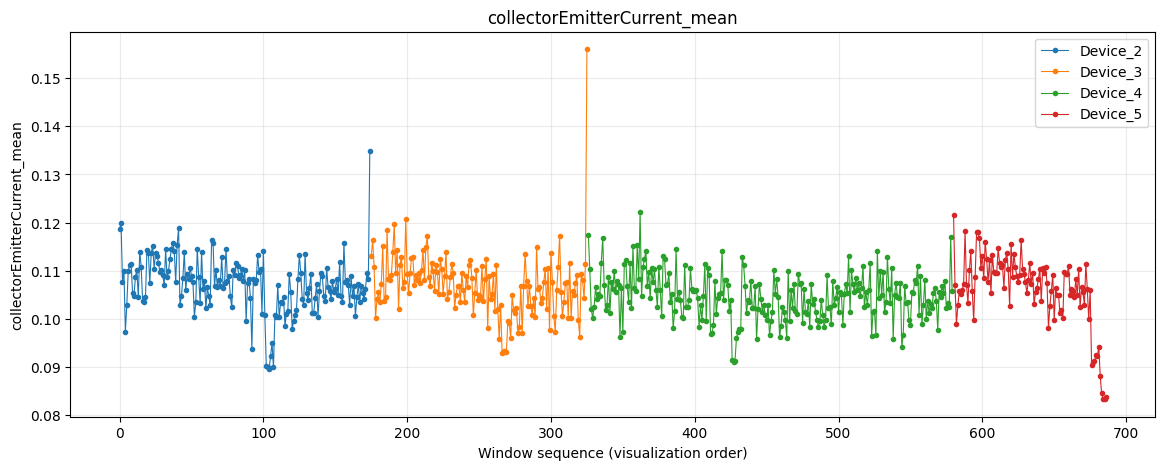

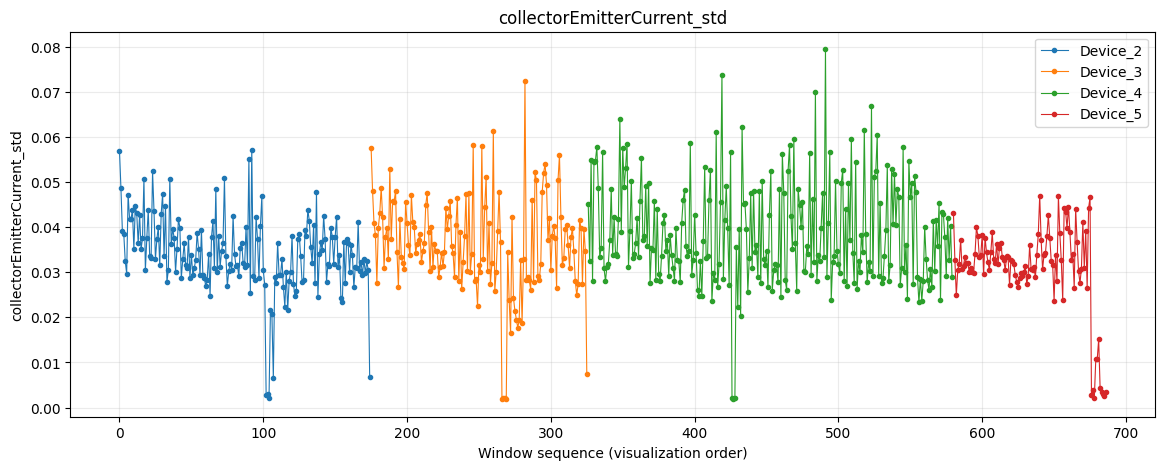

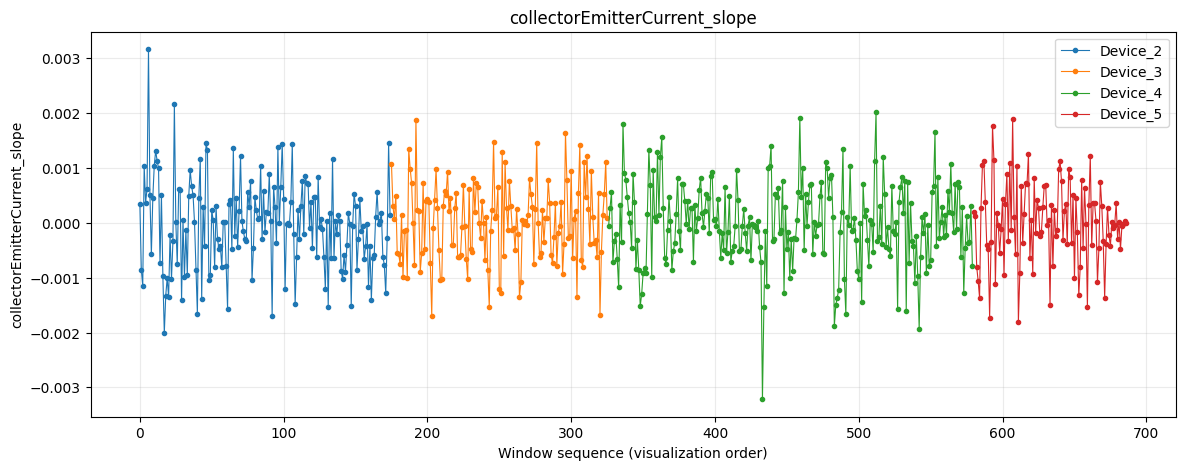

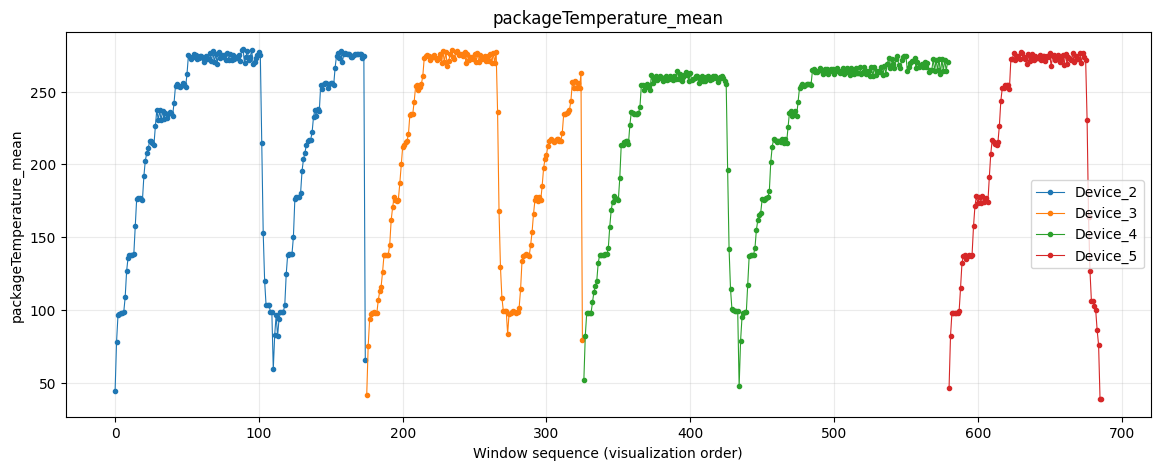

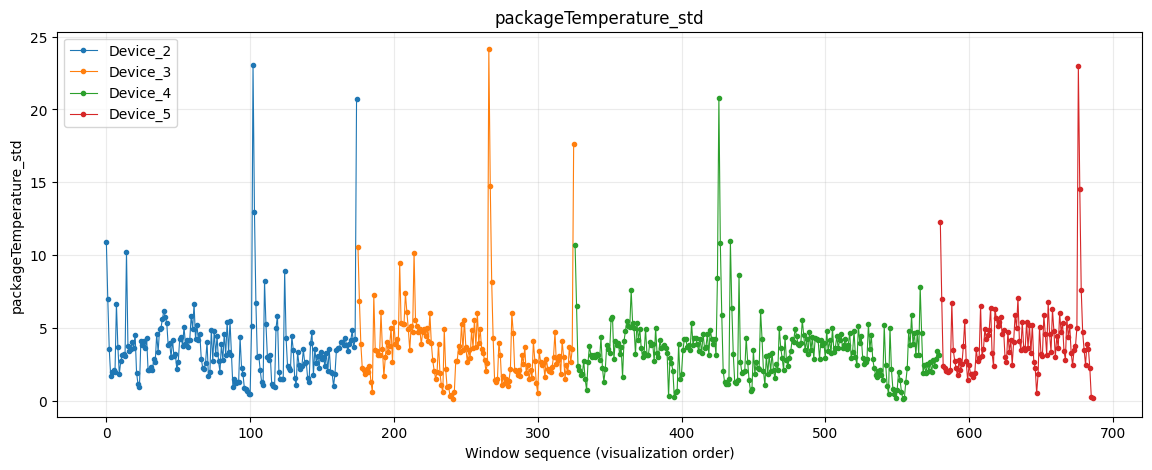

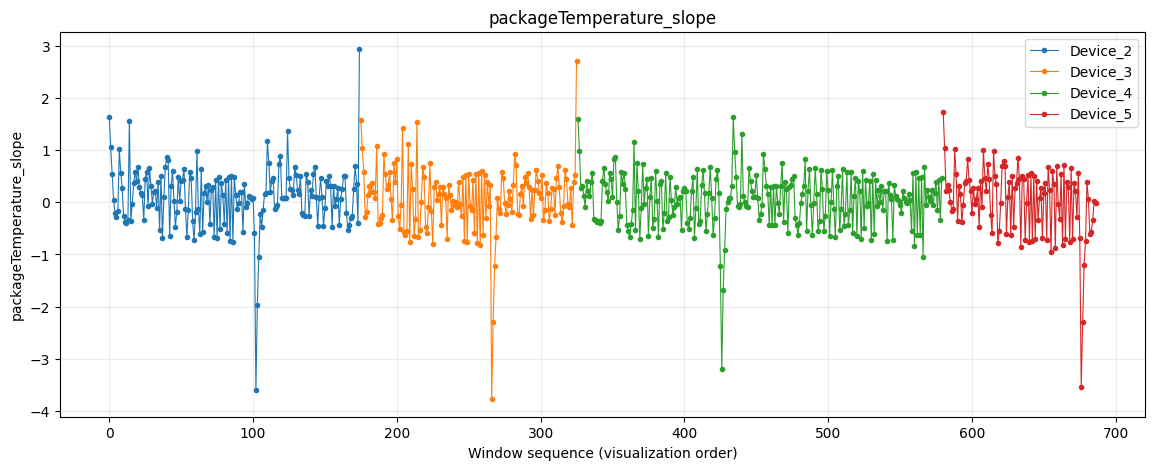

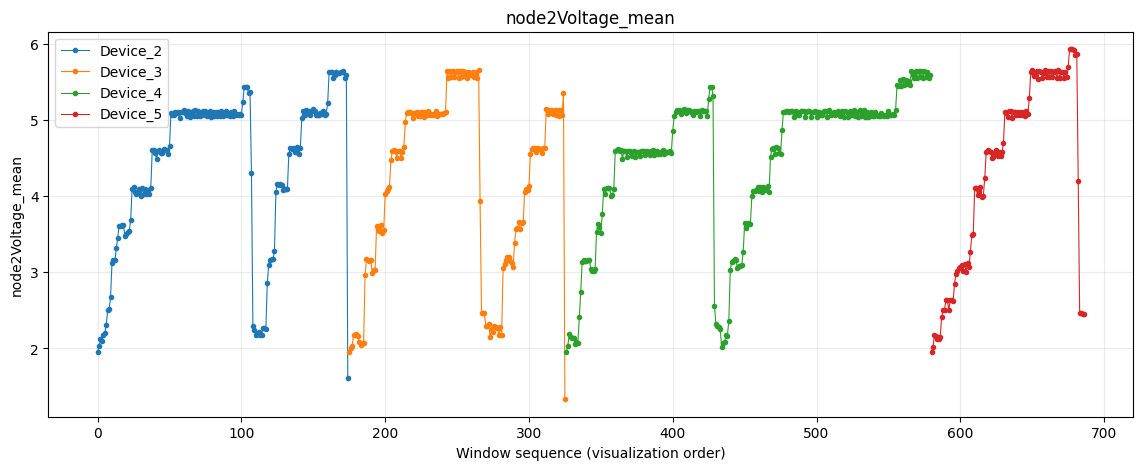

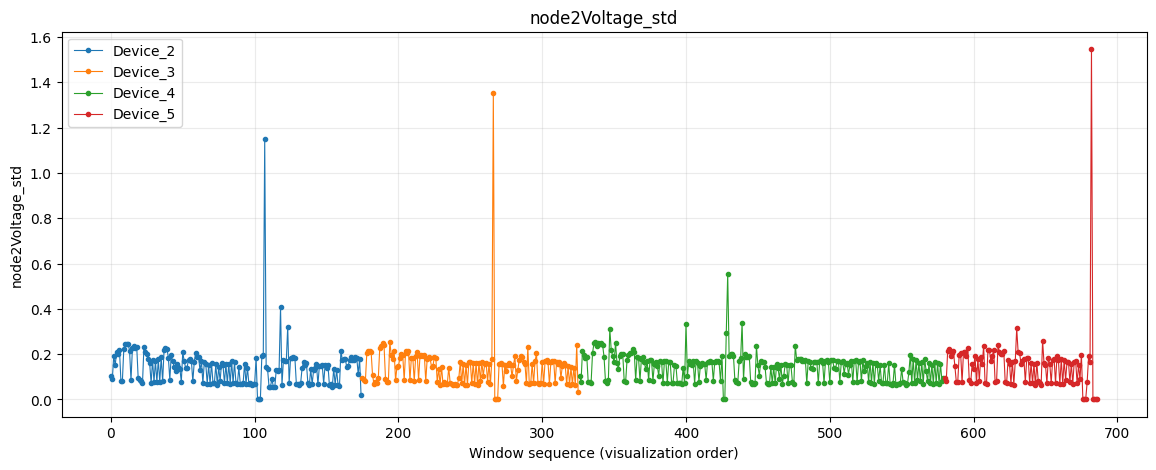

In [12]:
trend_features = [
    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_slope",
    "packageTemperature_mean",
    "packageTemperature_std",
    "packageTemperature_slope",
    "node2Voltage_mean",
    "node2Voltage_std",
]

trend_features = [
    c for c in trend_features if c in features.columns
]

for signal_feature in trend_features:
    fig, ax = plt.subplots(figsize=(14, 5))

    for device_id, group in features.groupby("device_id"):
        group = group.sort_values(
            ["file_name", "window_start_seconds"]
        )

        ax.plot(
            group.index,
            group[signal_feature],
            marker=".",
            linewidth=0.8,
            label=device_id
        )

    ax.set_title(signal_feature)
    ax.set_xlabel("Window sequence (visualization order)")
    ax.set_ylabel(signal_feature)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

# IMPORTANT: do not train yet

This feature matrix is **version 1**, not the final model input.

Before training we still need to answer:

1. What do the strange `heatSinkTemperature` and `internalTemperature` scales mean?
2. What exactly do `main`, `b`, and `check` represent according to the experiment documentation?
3. Which measurements are operating conditions versus component responses?
4. Should the model be trained on `main` only, `main+b`, or a conditionally normalized representation?
5. How should the 120 new-device SMU measurements be incorporated, if at all?
6. What constitutes a meaningful "normal" reference period?
7. How should test data be held out at the **device level** to avoid leakage?

Only after answering these questions will we train Isolation Forest and compare other unsupervised methods.